# Initialize

Purpose of helpers:

``experiment_utils.py``: Defines an ``Experiment`` class. Using it we can retrieve all parameter values, paths, load and reorder neurons, and other useful things even though each experiment is different. It has an iterator function so we can decide which levels to iterate through (simulations, pqif, seeds) and apply filters (e.g., only loop through all simulations and seeds for ``pqif=0.5`` and for the amplitudes in ``[8.0, 10.0]``). Initialized first and then whenever we use ``exp`` it contains all of that.

``iter_params``: Some example uses at the end. When we take out condition, ``p.condition`` is the condition object; ``p.condition.parameters`` is the dictionary containing its amplitude, sigma, offset. ``amplitude = p.condition.parameters["amplitude"]`` takes out amplitude within a given iteration.

Initialize:

In [5]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("plos.mplstyle")  # matplotlib style

# Import project files
cwd = Path.cwd().resolve()
project_dir = next((directory for directory in (cwd, *cwd.parents)if (directory / "experiment_utils.py").is_file()),None,)
if project_dir is None:
    raise FileNotFoundError("experiment_utils.py not found")
sys.path.insert(0, str(project_dir))
from experiment_utils import Experiment
import analysis.analysis_functions as af


# Initialize experiments ()
experiment_names = ["1003_sequences"]
exps = []
for experiment_name in experiment_names:
    exp = Experiment.find(experiment_name)
    exps.append(exp)

    print(f"{'-' * 50}\nInitialized experiment: {exp.name}")
    print(f"Location: {exp.directory}\n{'-' * 50}\n")

    print("\nExperiment parameters:")
    for key, value in exp.cfg.items():
        print(f"   {key}: {value}")

--------------------------------------------------
Initialized experiment: 1003_sequences
Location: C:\Users\snrambo\Projects\NEVR3901\HeterogenousRNN\HeterogeneousRNNs\learning\run_simulations\test\results\1003_sequences
--------------------------------------------------


Experiment parameters:
   master_seed: 1003
   target_dynamics: sequences
   N: 500
   pqif_values: [0.0, 0.5, 1.0]
   configs: [{'vt': 0.0, 'vreset': -21.0}]
   p: 1
   gsyn: 0.5
   alpha: 0.25
   dt: 0.1
   itmax: 1000
   sigman: 1.0
   ts: 5.0
   itstim: 200
   current_amplitude: 24
   current_amplitude_by_pqif: None
   IEXT_LOW_FRAC: 0.0
   IEXT_HIGH_FRAC: 1.0
   nloop: 16
   nloop_train: 10
   cant_seed: 2
   ftrain: 1.0
   amp0: 4.0
   frequency_values: [1, 3, 5]
   number_sequences: 2
   sequence_amplitudes: [12.0]
   sequence_sigmas: [9.0]
   sequence_offsets: [0.0]
   sequence_ordering: random
   shared_sequence_order: False
   parallelize_seed: 1
   parallelize_pqif: 3
   parallelize_target_conditions: 1
 

# Evaluate training quality

In [ ]:
# Load target and network activity, and compare


# TODO put calculate_r2() and calculate_pearson() into analysis functions if we reuse them a lot
def calculate_r2(values, target):
    denominator = np.sum((target - target.mean()) ** 2)
    if denominator == 0:
        return np.nan
    return float(1 - np.sum((values - target) ** 2) / denominator)


def calculate_pearson(values, target):
    """Mean Pearson r across neurons. Arrays have shape (neurons, time)."""

    values = np.asarray(values, dtype=float)
    target = np.asarray(target, dtype=float)

    values = values - values.mean(axis=1, keepdims=True)
    target = target - target.mean(axis=1, keepdims=True)

    numerator = np.sum(values * target, axis=1)
    denominator = np.sqrt(
        np.sum(values ** 2, axis=1) *
        np.sum(target ** 2, axis=1)
    )

    correlations = np.divide(
        numerator, denominator,
        out=np.full(values.shape[0], np.nan),
        where=denominator > 0
    )

    valid = np.isfinite(correlations)
    return float(correlations[valid].mean()) if valid.any() else np.nan




exp = Experiment.find("1003_sequences")
iloop = 11

rows = []



for p in exp.iter_params("condition", "sim", "pqif", "seed"):


    # Load target and target parameters
    target, parameters = exp.load_target(p.condition, p.sim, p.pqif, p.seed, reorder=True, include_itstim=False)

    # Load recurrent input and output of the network
    recurrent, output = exp.load_network(
        p.condition, p.sim, p.pqif, p.seed,
        reorder=True, include_itstim=False,
        iloop=iloop
        )

    row = {
        "condition_id": p.condition.id,
        **p.condition.parameters,
        "sim": p.sim,
        "pqif": p.pqif,
        "seed": p.seed,
        "iloop": iloop,
        "vreset": exp.get_vreset(p.condition, sim=p.sim),
    }

    for name, values in {
        "target": target,
        "recurrent": recurrent,
        "output": output,
    }.items():

        row[f"{name}_r"] = calculate_pearson(values, target)  # compute pearson r
        row[f"{name}_r2"] = calculate_r2(values, target)  # compute r^2

    rows.append(row)

metrics = pd.DataFrame(rows)

csv_path = exp.directory / f"{exp.name}_activity_correlations_iloop_{iloop}.csv"
metrics.to_csv(csv_path, index=False)

print(f"Saved {len(metrics)} combinations to:")
print(csv_path)

display(metrics.head(20))



Saved 6 combinations to:
C:\Users\snrambo\Projects\NEVR3901\HeterogenousRNN\HeterogeneousRNNs\learning\run_simulations\test\results\1003_sequences\1003_sequences_activity_correlations_iloop_11.csv


,condition_id,amplitude,sigma,offset,sim,pqif,seed,iloop,vreset,target_r,target_r2,recurrent_r,recurrent_r2,output_r,output_r2
0,0,12.0,9.0,0.0,1,0.0,0,11,-16.0,1.0,1.0,0.953457,0.687583,0.838936,-1.163606
1,0,12.0,9.0,0.0,1,0.0,1,11,-16.0,1.0,1.0,0.944264,0.604126,0.869732,-1.159146
2,0,12.0,9.0,0.0,1,0.5,0,11,-16.0,1.0,1.0,0.948542,0.546800,0.865991,-1.188798
3,0,12.0,9.0,0.0,1,0.5,1,11,-16.0,1.0,1.0,0.957512,0.866591,0.674715,-1.198911
4,0,12.0,9.0,0.0,1,1.0,0,11,-16.0,1.0,1.0,0.972209,0.675348,0.694484,-1.238929
5,0,12.0,9.0,0.0,1,1.0,1,11,-16.0,1.0,1.0,0.509007,0.226258,0.217364,-1.224232


# Plot target vs input vs output

In [10]:
exp.cant_seed

2

Plotting seed 0


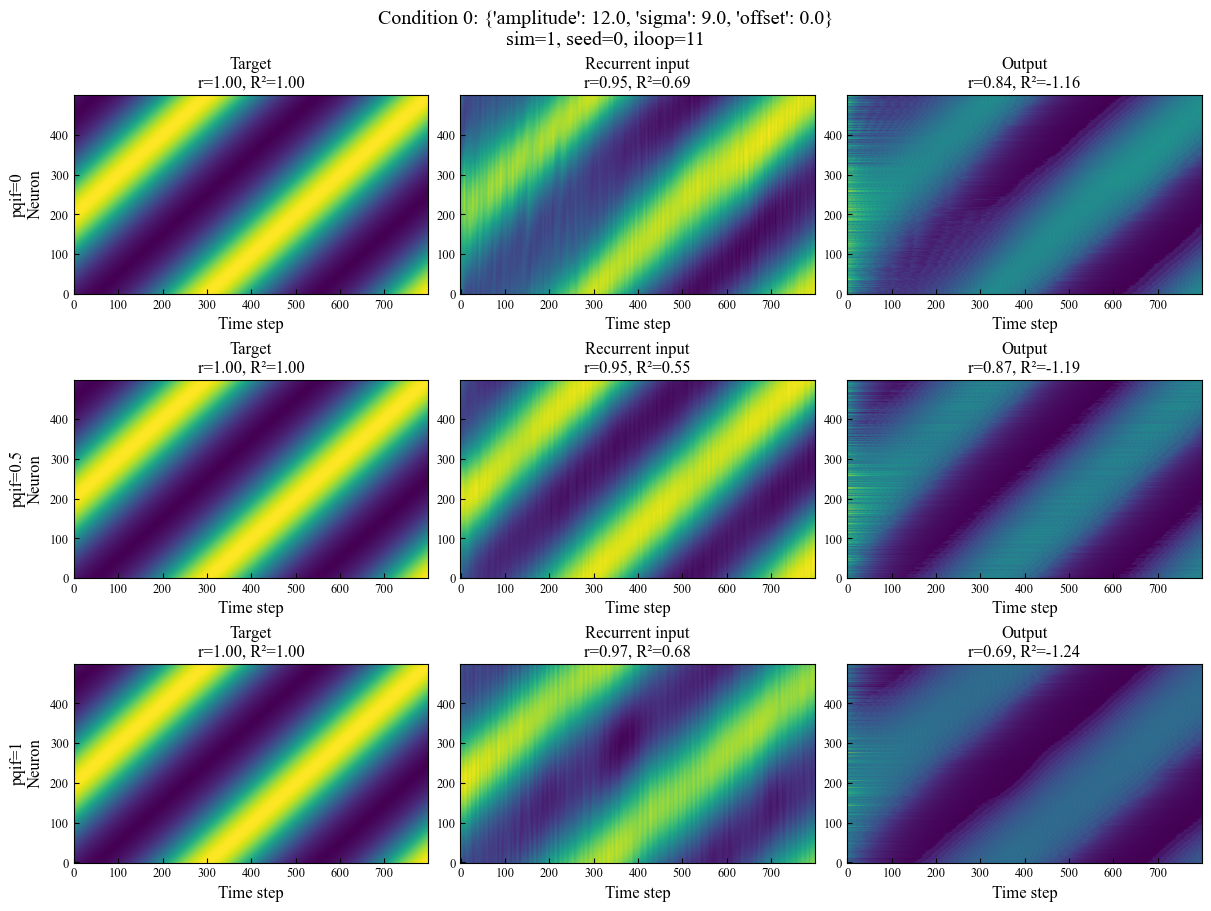

In [ ]:
import random

random_seed = random.randrange(exp.cant_seed)
sim = 1

print(f"Plotting seed {random_seed}")

metrics = pd.read_csv(exp.directory / f"{exp.name}_activity_correlations_iloop_{iloop}.csv")

for c in exp.iter_params("condition"):

    combinations = list(
        exp.iter_params(
            "condition", "sim", "pqif",
            condition=c.condition.id, sim=sim,
        )
    )

    fig, axes = plt.subplots(
        nrows=len(combinations),
        ncols=3,
        figsize=(12, 3 * len(combinations)),
        squeeze=False,
        constrained_layout=True
    )

    for i, p in enumerate(combinations):

        target, parameters = exp.load_target(p.condition, p.sim, p.pqif, random_seed)

        recurrent, output = exp.load_network(p.condition, p.sim, p.pqif, random_seed,iloop=iloop)

        # Find the correlation values
        match = metrics.loc[
            (metrics["condition_id"] == p.condition.id) &
            (metrics["sim"] == p.sim) &
            np.isclose(metrics["pqif"], p.pqif) &
            (metrics["seed"] == random_seed) &
            (metrics["iloop"] == iloop)
        ]

        if len(match) != 1:
            raise ValueError(f"Expected one metrics row, found {len(match)}")

        m = match.iloc[0]


        # Plot for each 

        for j, (name, values, prefix) in enumerate([
            ("Target", target, "target"),
            ("Recurrent input", recurrent, "recurrent"),
            ("Output", output, "output"),
        ]):
            ax = axes[i, j]
            ax.imshow(values, aspect="auto", origin="lower", cmap="viridis")
            ax.set_title(
                f"{name}\nr={m[f'{prefix}_r']:.2f}, R²={m[f'{prefix}_r2']:.2f}"
            )
            ax.set_xlabel("Time step")

            if j == 0:
                ax.set_ylabel(f"pqif={p.pqif:g}\nNeuron")

    fig.suptitle(
        f"Condition {c.condition.id}: {c.condition.parameters}\n"
        f"sim={sim}, seed={random_seed}, iloop={iloop}"
    )

    plt.show()

In [23]:
metrics

,condition_id,amplitude,sigma,offset,sim,pqif,seed,iloop,vreset,target_r,target_r2,recurrent_r,recurrent_r2,output_r,output_r2
0,0,12.0,9.0,0.0,1,0.0,0,11,-16.0,1.0,1.0,0.953457,0.687583,0.838936,-1.163606
1,0,12.0,9.0,0.0,1,0.0,1,11,-16.0,1.0,1.0,0.944264,0.604126,0.869732,-1.159146
2,0,12.0,9.0,0.0,1,0.5,0,11,-16.0,1.0,1.0,0.948542,0.546800,0.865991,-1.188798
3,0,12.0,9.0,0.0,1,0.5,1,11,-16.0,1.0,1.0,0.957512,0.866591,0.674715,-1.198911
4,0,12.0,9.0,0.0,1,1.0,0,11,-16.0,1.0,1.0,0.972209,0.675348,0.694484,-1.238929
5,0,12.0,9.0,0.0,1,1.0,1,11,-16.0,1.0,1.0,0.509007,0.226258,0.217364,-1.224232


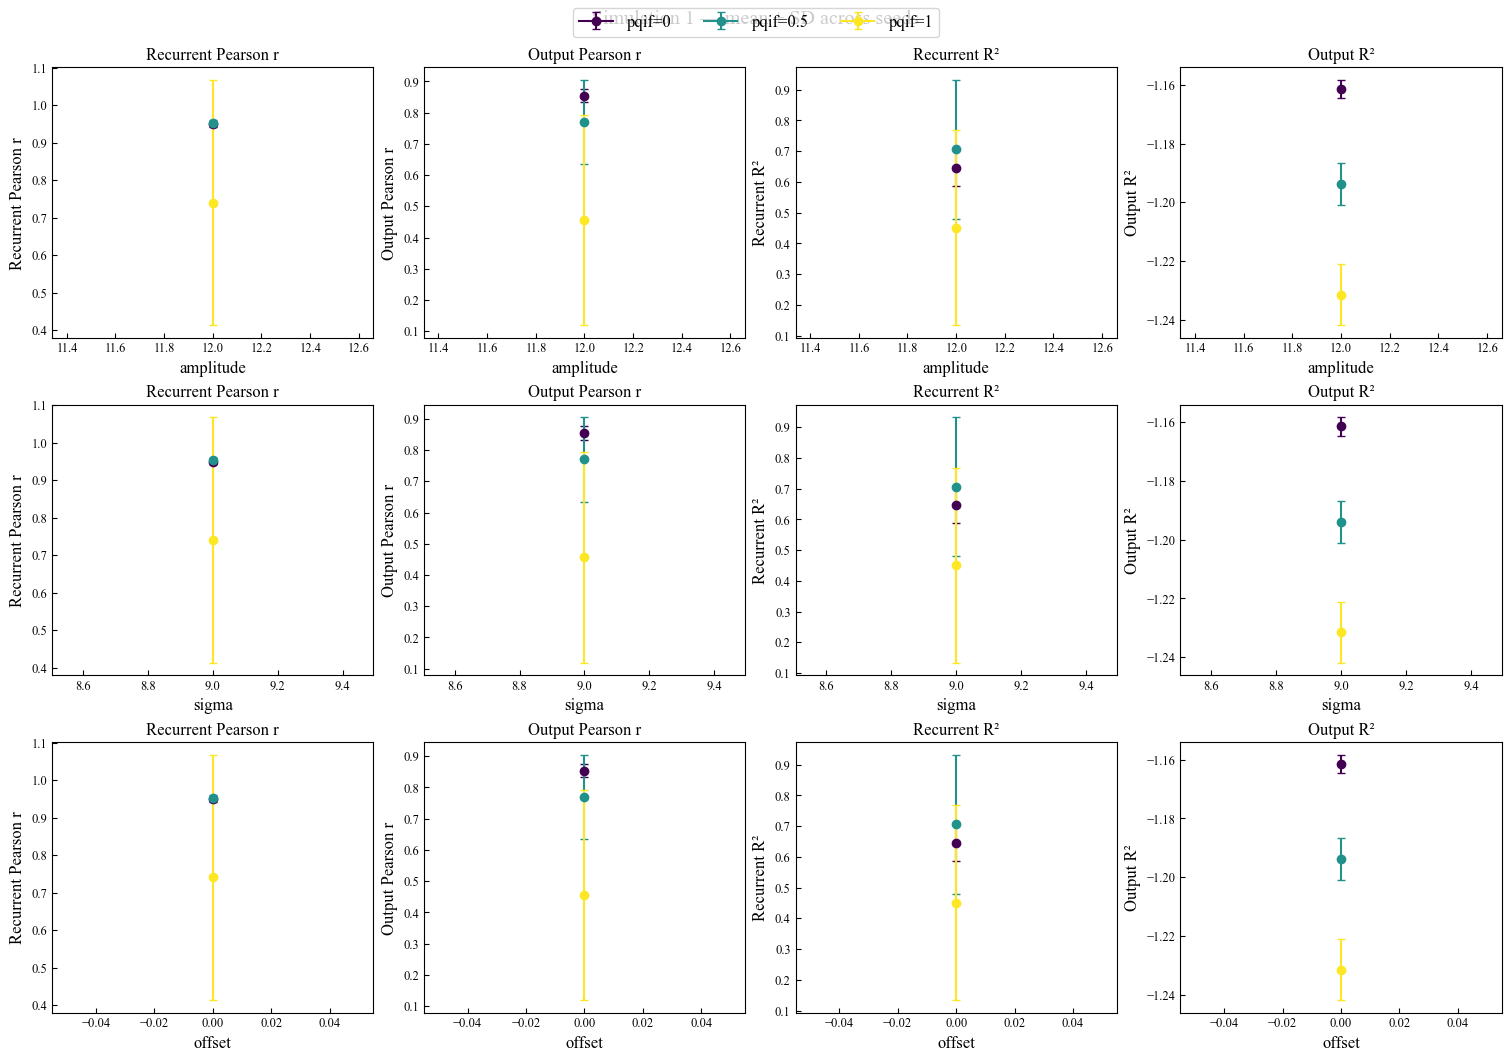

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

metrics = pd.read_csv(exp.directory / f"{exp.name}_activity_correlations_iloop_{iloop}.csv")

fixed = {
    "amplitude": 12.0,
    "sigma": 9.0,
    "offset": 0.0,
}

measures = {
    "recurrent_r": "Recurrent Pearson r",
    "output_r": "Output Pearson r",
    "recurrent_r2": "Recurrent R²",
    "output_r2": "Output R²",
}

pqif_values = sorted(metrics["pqif"].unique())
colors = plt.get_cmap("viridis")(np.linspace(0, 1, len(pqif_values)))

for sim in sorted(metrics["sim"].unique()):

    fig, axes = plt.subplots(
        nrows=len(fixed),
        ncols=len(measures),
        figsize=(15, 3.5 * len(fixed)),
        squeeze=False,
        constrained_layout=True
    )

    for i, varying in enumerate(fixed):

        # Keep all other parameters fixed
        df = metrics[metrics["sim"] == sim].copy()

        for name, value in fixed.items():
            if name != varying:
                df = df[np.isclose(df[name], value)]

        # Average across seeds for each parameter value and pqif
        summary = df.groupby([varying, "pqif"])[list(measures)].agg(["mean", "std"])

        for j, (measure, title) in enumerate(measures.items()):
            ax = axes[i, j]

            for pqif, color in zip(pqif_values, colors):
                if pqif not in summary.index.get_level_values("pqif"):
                    continue

                data = summary.xs(pqif, level="pqif").sort_index()

                ax.errorbar(
                    data.index,
                    data[(measure, "mean")],
                    yerr=data[(measure, "std")].fillna(0),
                    marker="o",
                    capsize=3,
                    color=color,
                    label=f"pqif={pqif:g}"
                )

            ax.set_xlabel(varying)
            ax.set_ylabel(title)
            ax.set_title(title)

    fig.suptitle(f"Simulation {sim} — mean ± SD across seeds")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside upper center", ncol=len(pqif_values))

    plt.show()

# Example uses of iter_params()

In [ ]:
metrics = pd.read_csv(exp.directory / f"{exp.name}_activity_correlations_iloop_{iloop}.csv")

for c in exp.iter_params("condition"):
    amplitude = p.condition.parameters["amplitude"]
    sigma = p.condition.parameters["sigma"]
    offset = p.condition.parameters["offset"]

    print(amplitude, sigma, offset)

{'amplitude': 12.0, 'sigma': 9.0, 'offset': 0.0}


In [30]:
for p in exp.iter_params("condition"):
    print(f"Condition {p.condition.id}")

    for name, value in p.condition.parameters.items():
        print(f"  {name}: {value}")

Condition 0
  amplitude: 12.0
  sigma: 9.0
  offset: 0.0


In [ ]:
# Find condition ids with specific parameter values

for p in exp.iter_params("condition", amplitude=12, sigma=9):
    print(p.condition.id, p.condition.parameters)

0 {'amplitude': 12.0, 'sigma': 9.0, 'offset': 0.0}
